In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.metrics import f1_score
from sklearn.metrics import ConfusionMatrixDisplay, roc_auc_score
from sklearn.ensemble import RandomForestClassifier

# Part 1. Overview and preliminary analysis of the data

In [2]:
df = pd.read_csv('bank.csv')

In [3]:
df.shape

(11162, 17)

In [4]:
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 11162 entries, 0 to 11161
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        11162 non-null  int64
 1   job        11162 non-null  str  
 2   marital    11162 non-null  str  
 3   education  11162 non-null  str  
 4   default    11162 non-null  str  
 5   balance    11162 non-null  int64
 6   housing    11162 non-null  str  
 7   loan       11162 non-null  str  
 8   contact    11162 non-null  str  
 9   day        11162 non-null  int64
 10  month      11162 non-null  str  
 11  duration   11162 non-null  int64
 12  campaign   11162 non-null  int64
 13  pdays      11162 non-null  int64
 14  previous   11162 non-null  int64
 15  poutcome   11162 non-null  str  
 16  deposit    11162 non-null  str  
dtypes: int64(7), str(10)
memory usage: 2.0 MB


In [6]:
df.isna().sum()

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
deposit      0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,11162.000000,11162.000000,11162.000000,11162.000000,11162.000000,11162.000000,11162.000000
mean,41.231948,1528.538524,15.658036,371.993818,2.508421,51.330407,0.832557
std,11.913369,3225.413326,8.420740,347.128386,2.722077,108.758282,2.292007
min,18.000000,-6847.000000,1.000000,2.000000,1.000000,-1.000000,0.000000
25%,32.000000,122.000000,8.000000,138.000000,1.000000,-1.000000,0.000000
50%,39.000000,550.000000,15.000000,255.000000,2.000000,-1.000000,0.000000
75%,49.000000,1708.000000,22.000000,496.000000,3.000000,20.750000,1.000000
max,95.000000,81204.000000,31.000000,3881.000000,63.000000,854.000000,58.000000


In [9]:
print("Distribution of the target variable:")
print(df['deposit'].value_counts(normalize=True) * 100)
categorical_cols = df.select_dtypes(include=['str', 'object']).columns
for col in categorical_cols:
    unknown_count = (df[col] == 'unknown').sum()
    if unknown_count > 0:
        print(f"Column '{col}': {unknown_count} values of 'unknown' ({unknown_count/len(df)*100:.2f}%)")

Distribution of the target variable:
deposit
no     52.616019
yes    47.383981
Name: proportion, dtype: float64
Column 'job': 70 values of 'unknown' (0.63%)
Column 'education': 497 values of 'unknown' (4.45%)
Column 'contact': 2346 values of 'unknown' (21.02%)
Column 'poutcome': 8326 values of 'unknown' (74.59%)


Conclusions on the first part

The dataset contains 11,162 rows and 17 columns. It also includes 7 numeric and 10 categorical data types. No missing values or duplicates were identified during the analysis. In this dataset, the target variable is ‘deposit’. It is balanced at 52% to 47%. Therefore, the data does not require the application of special balancing methods.

However, there are ‘unknown’ missing values: in the ‘job’ column – up to one per cent; in ‘education’ – 4 per cent; in ‘contact’ – 21 per cent; and in ‘outcome’ – 74 per cent. In the first two columns, the proportion is insignificant, whilst in the latter two there is a significant number of missing values. This will need to be taken into account during one-hot encoding.

There are also outliers and anomalous values. In the ‘balance’ column, the median is just 550, whilst the mean is 1,528 (maximum 81,204, minimum –6,847). For ‘duration’, the maximum call duration is 3,881 seconds (~64 minutes) with a median of 255 seconds. For  campaign’, 75 per cent of customers had up to 3 contacts, but there are outliers of up to 63 contacts. For ‘pdays’, a value of -1 indicates no previous contact.


# Part 2. Data visualisation

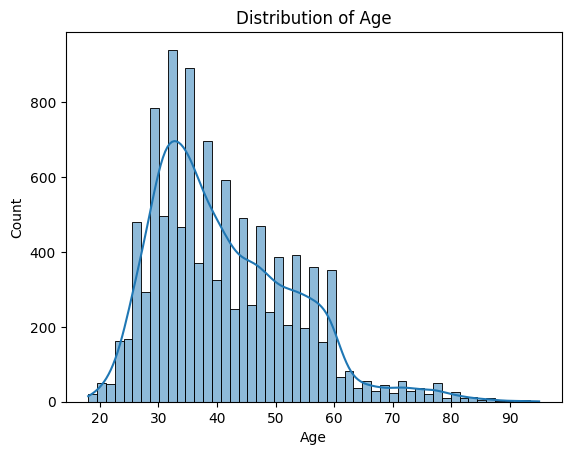

In [10]:
sns.histplot(df['age'], kde=True)
plt.title('Distribution of Age')
plt.xlabel('Age')
plt.ylabel('Count')
plt.show()

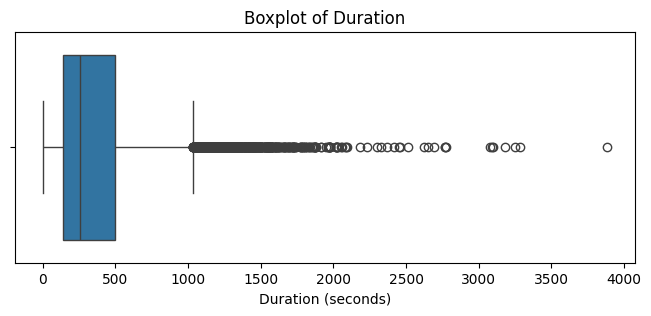

In [11]:
plt.figure(figsize=(8, 3))
sns.boxplot(x=df['duration'])
plt.title('Boxplot of Duration')
plt.xlabel('Duration (seconds)')
plt.show()

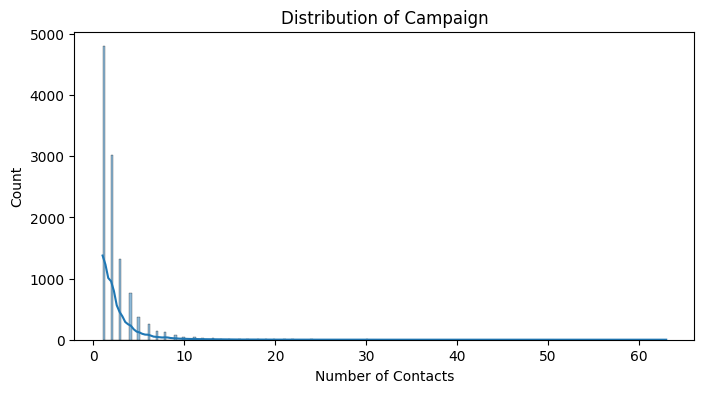

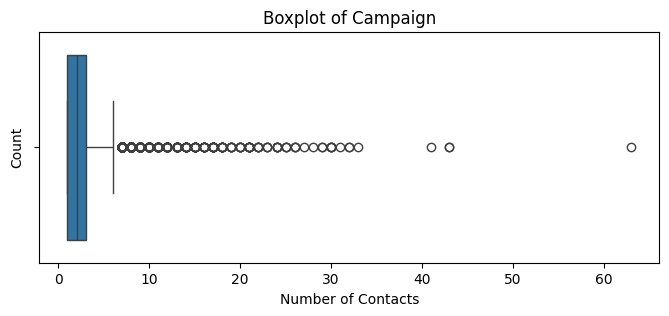

In [12]:
plt.figure(figsize=(8, 4))
sns.histplot(df['campaign'], kde=True)
plt.title('Distribution of Campaign')
plt.xlabel('Number of Contacts')
plt.ylabel('Count')

plt.figure(figsize=(8, 3))
sns.boxplot(x=df['campaign'])
plt.title('Boxplot of Campaign')
plt.xlabel('Number of Contacts')
plt.ylabel('Count')

plt.show()

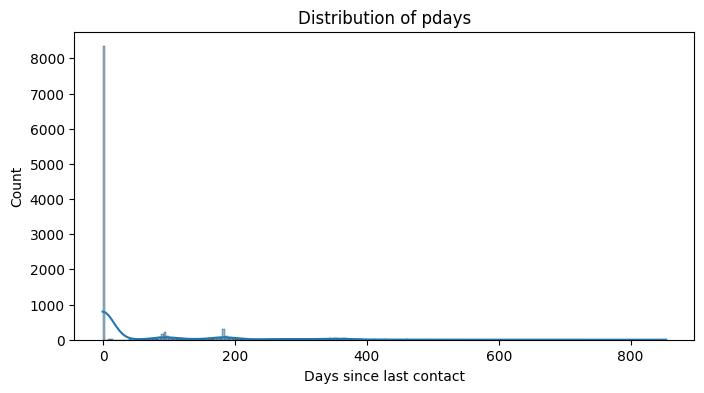

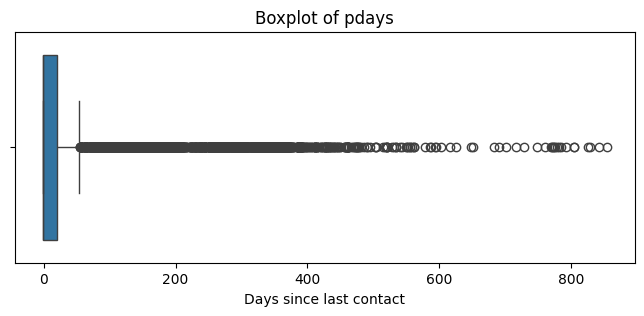

In [13]:
plt.figure(figsize=(8, 4))
sns.histplot(df['pdays'], kde=True)
plt.title('Distribution of pdays')
plt.xlabel('Days since last contact')
plt.ylabel('Count')

plt.figure(figsize=(8, 3))
sns.boxplot(x=df['pdays'])
plt.title('Boxplot of pdays')
plt.xlabel('Days since last contact')
plt.show()

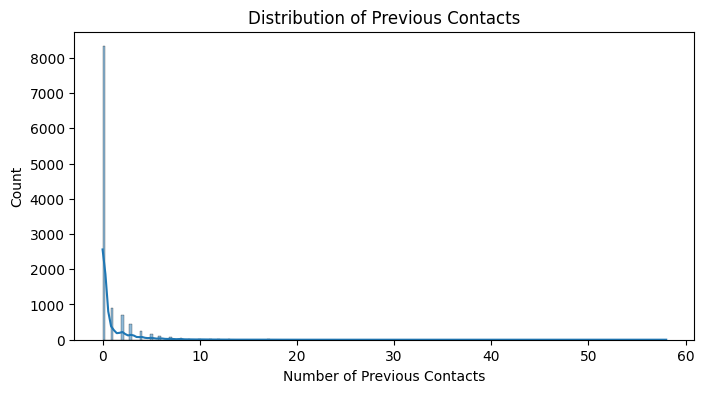

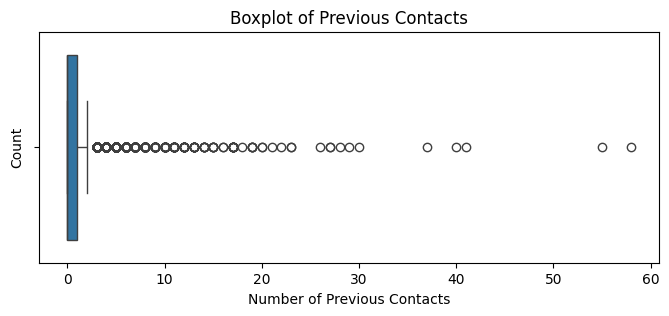

In [14]:
plt.figure(figsize=(8, 4))
sns.histplot(df['previous'], kde=True)
plt.title('Distribution of Previous Contacts')
plt.xlabel('Number of Previous Contacts')
plt.ylabel('Count')

plt.figure(figsize=(8, 3))
sns.boxplot(x=df['previous'])
plt.title('Boxplot of Previous Contacts')
plt.xlabel('Number of Previous Contacts')
plt.ylabel('Count')
plt.show()

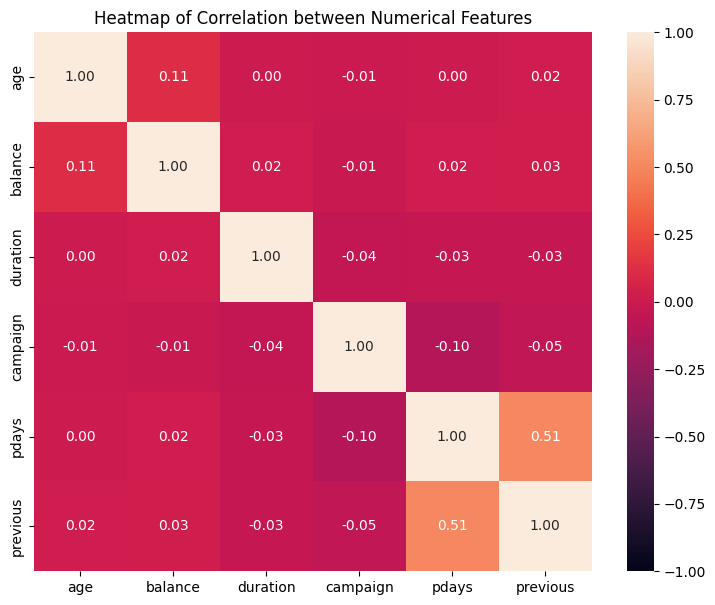

In [15]:
num_cols = ['age', 'balance', 'duration', 'campaign', 'pdays', 'previous']

plt.figure(figsize=(9, 7))
sns.heatmap(df[num_cols].corr(), annot=True, fmt='.2f', vmin=-1, vmax=1)
plt.title('Heatmap of Correlation between Numerical Features')
plt.show()

C:\Temp\ipykernel_5192\88502362.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='deposit', y='duration', palette='Set2')


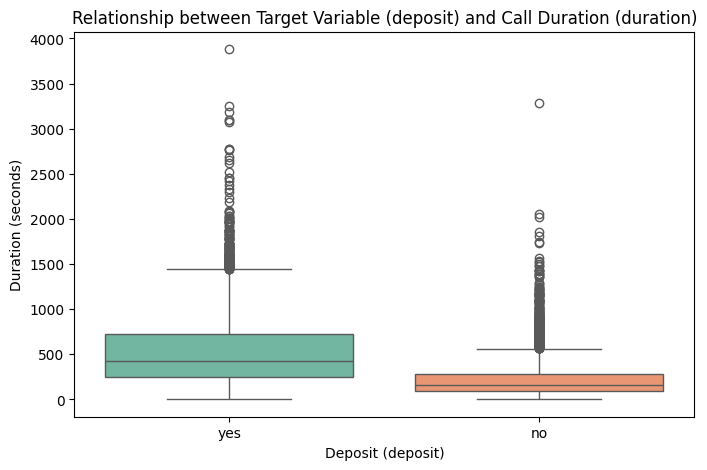

In [16]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='deposit', y='duration', palette='Set2')
plt.title('Relationship between Target Variable (deposit) and Call Duration (duration)')
plt.xlabel('Deposit (deposit)')
plt.ylabel('Duration (seconds)')
plt.show()


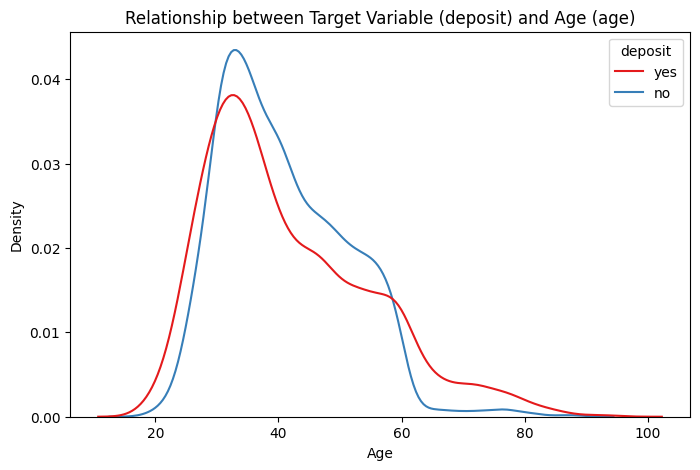

In [17]:
plt.figure(figsize=(8, 5))
sns.kdeplot(data=df, x='age', hue='deposit', common_norm=False, palette='Set1')
plt.title('Relationship between Target Variable (deposit) and Age (age)')
plt.xlabel('Age')
plt.ylabel('Density')
plt.show()

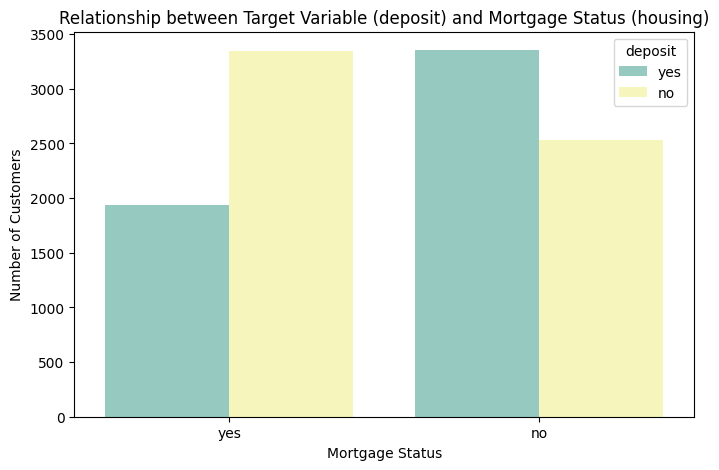

In [18]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='housing', hue='deposit', palette='Set3')
plt.title('Relationship between Target Variable (deposit) and Mortgage Status (housing)')
plt.xlabel('Mortgage Status')
plt.ylabel('Number of Customers')
plt.show()

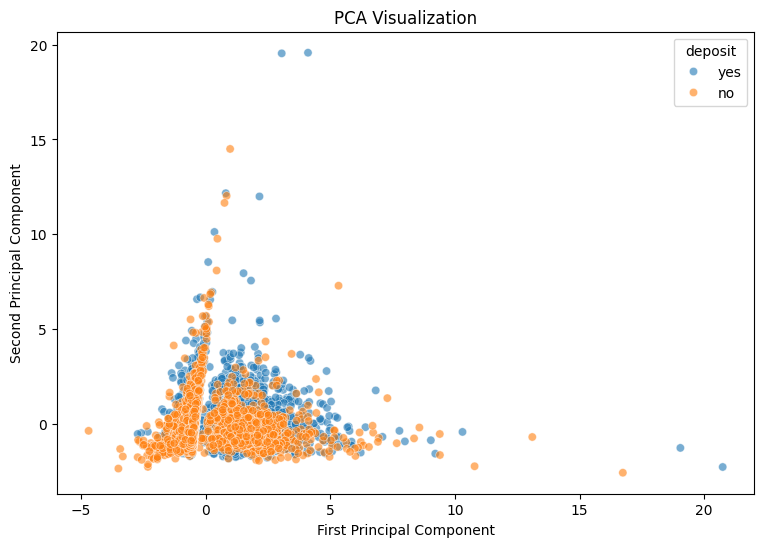

In [19]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[num_cols])

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(X_pca, columns=['PCA1', 'PCA2'])
pca_df['deposit'] = df['deposit']

plt.figure(figsize=(9, 6))
sns.scatterplot(data=pca_df, x='PCA1', y='PCA2', hue='deposit', alpha=0.6)
plt.title('PCA Visualization')
plt.xlabel('First Principal Component')
plt.ylabel('Second Principal Component')
plt.show()

Text(0.5, 1.0, 'Boxplot for Detecting Outliers: Balance')

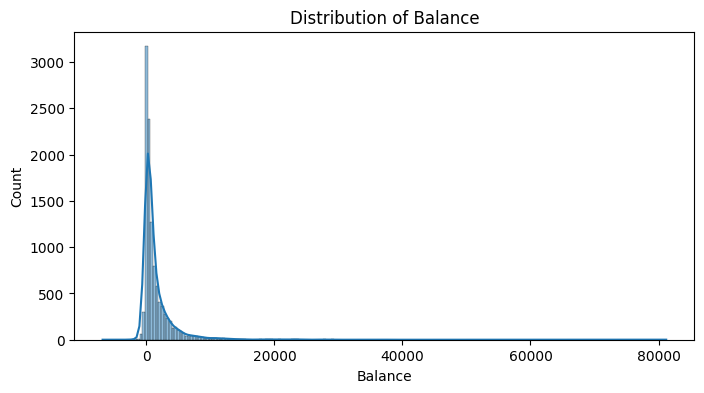

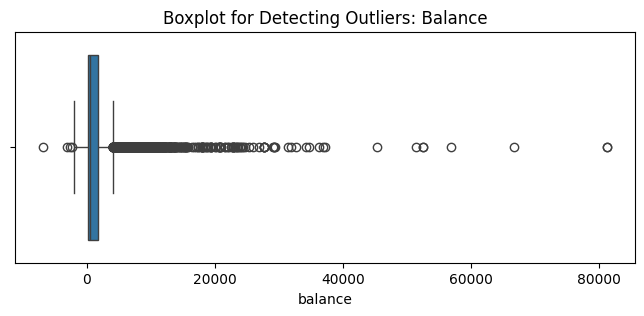

In [20]:
plt.figure(figsize=(8,4))
sns.histplot(df['balance'], kde=True)
plt.title('Distribution of Balance')
plt.xlabel('Balance')
plt.ylabel('Count')

plt.figure(figsize=(8,3))
sns.boxplot(x=df['balance'])
plt.title('Boxplot for Detecting Outliers: Balance')

The distributions of the numerical features confirmed the observations from the first section: ‘age’ and ‘duration’ exhibit right-skewed distributions, whilst ‘campaign’, ‘previous’ and, in particular, ‘balance’ contain a significant number of outliers. ‘pdays’ has an atypical distribution due to the large number of values of -1; therefore, this peak is not an outlier in the classical sense, but a separate category.

The correlation heatmap showed that the linear relationships between numerical features are weak – the strongest correlation between pdays and previous is explained by the fact that both features describe the history of previous contacts. This means that multicollinearity is not an issue for further modelling.

An analysis of the target variable’s dependencies revealed that duration has the strongest association with deposit; customers who agreed to a deposit had noticeably longer calls, whilst age and housing have a weaker influence but also demonstrate noticeable differences between groups.

The visualisation following PCA (2 components) did not reveal a clear linear separation of the ‘deposit’ classes – the points for both classes overlap to a significant extent, indicating the non-linear nature of the relationship between the target variable and the features, and justifying the need for models capable of capturing this type of non-linear relationship.


# Part 3: Data pre-processing

In [21]:
X = df.drop(['deposit', 'duration'], axis=1)
y = df['deposit'].map({'yes': 1, 'no': 0})

In [22]:
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.15, random_state=42, stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.176, random_state=42, stratify=y_temp
)

In [23]:
X_train.describe()

,age,balance,day,campaign,pdays,previous
count,7817.000000,7817.000000,7817.000000,7817.000000,7817.000000,7817.000000
mean,41.119611,1483.543559,15.676091,2.508379,51.518869,0.832544
std,11.878765,3090.655653,8.395238,2.783508,108.775573,2.278347
min,18.000000,-6847.000000,1.000000,1.000000,-1.000000,0.000000
25%,32.000000,116.000000,8.000000,1.000000,-1.000000,0.000000
50%,39.000000,553.000000,15.000000,2.000000,-1.000000,0.000000
75%,49.000000,1697.000000,22.000000,3.000000,17.000000,1.000000
max,95.000000,81204.000000,31.000000,63.000000,842.000000,58.000000


In [24]:
num_cols = ['age', 'balance', 'campaign', 'previous']  

outlier_bounds = {}
for col in num_cols:
    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outlier_bounds[col] = (lower, upper)

for col, (lower, upper) in outlier_bounds.items():
    X_train[col] = X_train[col].clip(lower, upper)
    X_val[col]   = X_val[col].clip(lower, upper)
    X_test[col]  = X_test[col].clip(lower, upper)

In [25]:
X_train['was_contacted_before'] = (X_train['pdays'] != -1).astype(int)
X_val['was_contacted_before']   = (X_val['pdays'] != -1).astype(int)
X_test['was_contacted_before']  = (X_test['pdays'] != -1).astype(int)

In [26]:
mode_job = X_train['job'].mode()[0]
X_train['job'] = X_train['job'].replace('unknown', mode_job)
X_val['job']   = X_val['job'].replace('unknown', mode_job)
X_test['job']  = X_test['job'].replace('unknown', mode_job)

In [27]:
cat_cols = X_train.select_dtypes(include=['object', 'str']).columns.tolist()

X_train_encoded = pd.get_dummies(X_train, columns=cat_cols, drop_first=True)
X_val_encoded   = pd.get_dummies(X_val, columns=cat_cols, drop_first=True)
X_test_encoded  = pd.get_dummies(X_test, columns=cat_cols, drop_first=True)

X_val_encoded   = X_val_encoded.reindex(columns=X_train_encoded.columns, fill_value=0)
X_test_encoded  = X_test_encoded.reindex(columns=X_train_encoded.columns, fill_value=0)

In [28]:

X_train_encoded['contact_intensity'] = X_train['campaign'] / (X_train['previous'] + 1)
X_val_encoded['contact_intensity']   = X_val['campaign'] / (X_val['previous'] + 1)
X_test_encoded['contact_intensity']  = X_test['campaign'] / (X_test['previous'] + 1)

In [29]:
scale_cols = ['age', 'balance', 'campaign', 'previous', 'pdays', 'contact_intensity']

scaler = StandardScaler()
X_train_encoded[scale_cols] = scaler.fit_transform(X_train_encoded[scale_cols])
X_val_encoded[scale_cols]   = scaler.transform(X_val_encoded[scale_cols])
X_test_encoded[scale_cols]  = scaler.transform(X_test_encoded[scale_cols])

As the feature `pdays` contains the value -1 for this column, this is a special indicator signifying that ‘there is no history’; if left as a normal number, the model will begin to search for a non-existent linear relationship between ‘number of days’ and the outcome. As our analysis shows that the vast majority of customers fall into this category, we need to extract this information into a separate binary feature, `was_contacted_before` (0/1), so that the model is trained separately on the presence or absence of prior contact, whilst the scaled value of `pdays` remains meaningful only for those who have actually been contacted previously. The second feature, `contact_intensity`, was calculated as the ratio of `campaign` to `previous` to reflect the relationship between the intensity of contact in the current campaign and the history of contact with that customer. A high value indicates that the customer is being actively contacted at present whilst having a weak previous history, whilst a low value indicates consistent interaction both now and in the past; a unit has been added to the denominator to avoid division by zero for customers with `previous=0`.

# Part 4. Clustering

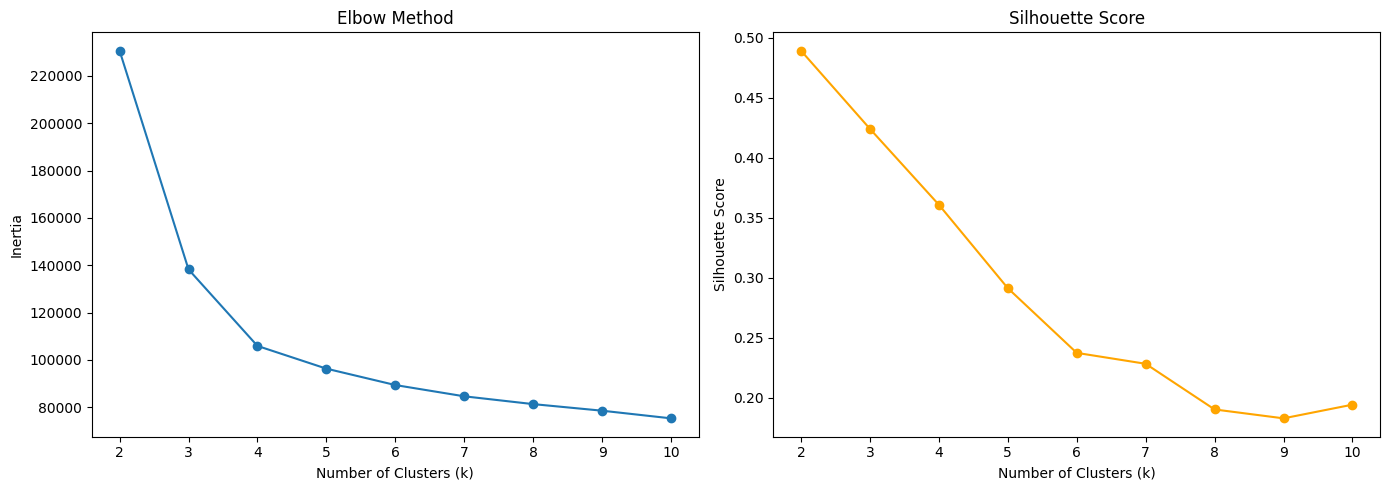

In [30]:

inertias = []
silhouettes = []
k_range = range(2, 11)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_train_encoded)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_train_encoded, labels))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(k_range, inertias, marker='o')
axes[0].set_title('Elbow Method')
axes[0].set_xlabel('Number of Clusters (k)')
axes[0].set_ylabel('Inertia')

axes[1].plot(k_range, silhouettes, marker='o', color='orange')
axes[1].set_title('Silhouette Score')
axes[1].set_xlabel('Number of Clusters (k)')
axes[1].set_ylabel('Silhouette Score')
plt.tight_layout()
plt.show()

In [31]:
cluster_features = X_train_encoded.drop(columns=['cluster'], errors='ignore')

In [32]:
optimal_k = 3

kmeans_final = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
cluster_labels = kmeans_final.fit_predict(cluster_features)

X_train_encoded['cluster'] = cluster_labels

In [33]:
profile_df = X_train.copy()
profile_df['cluster'] = cluster_labels

display(profile_df.groupby('cluster')[['age', 'balance', 'campaign', 'previous']].mean())

for col in ['job', 'marital', 'education', 'housing']:
    print(pd.crosstab(profile_df['cluster'], profile_df[col], normalize='index').round(2))
    
print(profile_df['cluster'].value_counts(normalize=True) * 100)

,age,balance,campaign,previous
cluster,,,,
0,41.045506,1032.374334,1.998858,0.542650
1,40.984612,1073.693239,2.505045,0.409435
2,41.074790,1178.246494,2.265503,0.486133


job      admin.  blue-collar  entrepreneur  housemaid  management  retired  \
cluster                                                                      
0          0.13         0.17          0.02       0.02        0.25     0.07   
1          0.12         0.14          0.02       0.03        0.26     0.07   
2          0.11         0.20          0.04       0.02        0.22     0.06   

job      self-employed  services  student  technician  unemployed  
cluster                                                            
0                 0.03      0.08     0.04        0.15        0.03  
1                 0.03      0.08     0.04        0.18        0.04  
2                 0.04      0.09     0.03        0.15        0.02  
marital  divorced  married  single
cluster                           
0            0.11     0.57    0.32
1            0.11     0.55    0.34
2            0.13     0.57    0.31
education  primary  secondary  tertiary  unknown
cluster                                      

In [34]:
cluster_target = pd.DataFrame({'cluster': cluster_labels, 'deposit': y_train.values})
crosstab_result = pd.crosstab(cluster_target['cluster'], cluster_target['deposit'], normalize='index') * 100
display(crosstab_result)

deposit,0,1
cluster,,
0,50.000000,50.000000
1,52.472250,47.527750
2,54.845746,45.154254


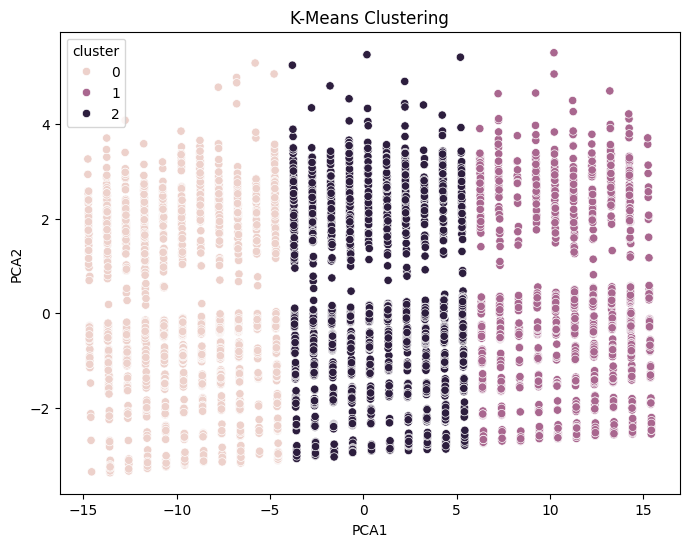

In [35]:
pca_cluster = PCA(n_components=2)
X_pca_cluster = pca_cluster.fit_transform(cluster_features)

pca_cluster_df = pd.DataFrame(X_pca_cluster, columns=['PCA1', 'PCA2'])
pca_cluster_df['cluster'] = cluster_labels

plt.figure(figsize=(8,6))
sns.scatterplot(data=pca_cluster_df, x='PCA1', y='PCA2', hue='cluster')
plt.title('K-Means Clustering')
plt.show()

The Elbow Method and Silhouette Score were used to determine the optimal number of clusters. Although the highest Silhouette Score is observed for k=2, this corresponds to the crudest possible division of the data in half and offers little analytical value for customer segmentation. At k=3, the Silhouette Score remains quite high, and it is at this value that the Elbow Method shows a bend in the graph: inertia falls from 238,000 to 146,000 when moving from k=2 to k=3, whilst a further increase in k to 4–5 or more yields a significantly smaller increase. Therefore, k=3 was selected. Three clusters were obtained, which are virtually indistinguishable in terms of numerical features - age, balance, duration, campaign and previous are almost identical across all three groups; however, they are clearly separated by the categorical feature ‘housing’: clusters 0 and 1 consist predominantly of customers without a mortgage, whilst cluster 2 consists predominantly of customers with a mortgage; Cluster 2 is also slightly smaller in size. An analysis of the relationship between the clusters and the target variable ‘deposit’ showed that the proportion of customers who agreed to make a deposit was virtually the same across all three clusters; in other words, no statistically significant relationship was found between the clusters identified and the campaign outcome. A likely reason for this is that, following one-hot encoding, the number of binary features (job, marital, education, contact, month, outcome) significantly exceeds the number of numerical features; and in the Euclidean distance minimised by K-Means, these variables dominate over the numerical behavioural features (call duration, number of contacts), which, according to the results of Parts 1–2, are in fact most strongly associated with ‘deposit’.

# Part 5. Building machine learning models

In [36]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

X_train_final = X_train_encoded.drop(columns=['cluster'], errors='ignore')
X_val_final   = X_val_encoded.drop(columns=['cluster'], errors='ignore')
X_test_final  = X_test_encoded.drop(columns=['cluster'], errors='ignore')

In [37]:
log_reg_params = {
    'C': [0.01, 0.1, 1, 10, 100]
}

log_reg_grid = GridSearchCV(
    LogisticRegression(max_iter=1000, random_state=42),
    param_grid=log_reg_params,
    cv=5,
    scoring='f1',
    n_jobs=-1
)
log_reg_grid.fit(X_train_final, y_train)

print("Best Logistic Regression:", log_reg_grid.best_params_)
print("Best F1 on CV:", log_reg_grid.best_score_)

log_reg_best = log_reg_grid.best_estimator_

Best Logistic Regression: {'C': 0.1}
Best F1 on CV: 0.6630316675158496


In [38]:
tree_params = {
    'max_depth': [3, 5, 7, 10, 15, None],
    'min_samples_leaf': [1, 5, 10, 20]
}

tree_grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid=tree_params,
    cv=5,
    scoring='f1',
    n_jobs=-1
)
tree_grid.fit(X_train_final, y_train)

print("Best Decision Tree parameters:", tree_grid.best_params_)
print("Best F1 on CV:", tree_grid.best_score_)

tree_best = tree_grid.best_estimator_

Best Decision Tree parameters: {'max_depth': None, 'min_samples_leaf': 20}
Best F1 on CV: 0.6567571362731388


In [39]:
from sklearn.model_selection import RandomizedSearchCV

rf_params = {
    'n_estimators': [100, 200, 300],
    'max_depth': [5, 10, 15, None],
    'min_samples_leaf': [5, 10, 20, 50]
}

rf_search = RandomizedSearchCV(
    RandomForestClassifier(random_state=42),
    param_distributions=rf_params,
    n_iter=15,
    cv=5,
    scoring='f1',
    random_state=42,
    n_jobs=-1
)
rf_search.fit(X_train_final, y_train)

print("Best Random Forest parameters:", rf_search.best_params_)
print("Best F1 on CV:", rf_search.best_score_)

rf_best = rf_search.best_estimator_

Best Random Forest parameters: {'n_estimators': 200, 'min_samples_leaf': 5, 'max_depth': None}
Best F1 on CV: 0.6839466098690841


In [40]:

X_trval = pd.concat([X_train_final, X_val_final])
y_trval = pd.concat([y_train, y_val])
final_rf = RandomForestClassifier(**rf_search.best_params_, random_state=42)
final_rf.fit(X_trval, y_trval)
print('Test F1 (final, train+val):', f1_score(y_test, final_rf.predict(X_test_final)))

Test F1 (final, train+val): 0.6848357791754018


# Part 6

In [41]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score
)
def evaluate_model(model, X, y, dataset_name, model_name):
    preds = model.predict(X)
    proba = model.predict_proba(X)[:, 1]
    return {
        'model': model_name,
        'dataset': dataset_name,
        'accuracy': accuracy_score(y, preds),
        'precision': precision_score(y, preds),
        'recall': recall_score(y, preds),
        'f1': f1_score(y, preds),
        'roc_auc': roc_auc_score(y, proba)
    }

models = {
    'Logistic Regression': log_reg_best,
    'Decision Tree': tree_best,
    'Random Forest': rf_search.best_estimator_
}

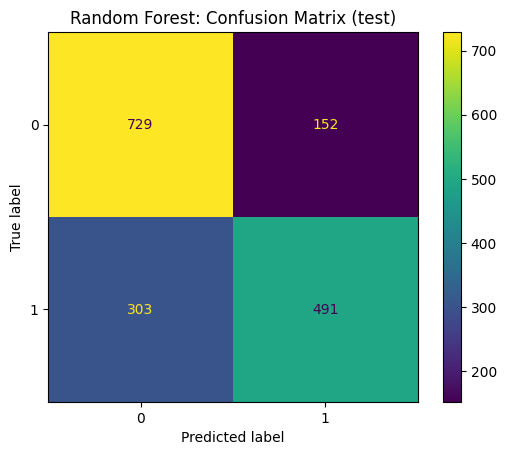

In [42]:
ConfusionMatrixDisplay.from_estimator(rf_search.best_estimator_, X_test_final, y_test)
plt.title('Random Forest: Confusion Matrix (test)')
plt.show()

Accuracy, Precision, Recall and F1-score were selected. As the target variable is almost balanced, Accuracy alone is insufficient because it does not indicate exactly what mistakes the model is making. The F1-score was chosen as the primary metric for comparing models, as it equally accounts for Precision (the proportion of customers labelled by the model as ‘agreeing to a deposit’ who actually did so) and Recall (the proportion of actual ‘agreeing’ customers that the model did not miss). Both types of error are critical for the bank: a missed potential customer—that is, low recall—means lost revenue, whilst an unnecessary call to an uninterested customer means wasted call centre resources.

In [43]:
lr_train = evaluate_model(log_reg_best, X_train_final, y_train, 'train', 'Logistic Regression')
lr_val   = evaluate_model(log_reg_best, X_val_final, y_val, 'validation', 'Logistic Regression')
lr_test  = evaluate_model(log_reg_best, X_test_final, y_test, 'test', 'Logistic Regression')

print("Logistic Regression:")
print(f"  train: F1 = {lr_train['f1']:.4f}, Accuracy = {lr_train['accuracy']:.4f}, Precision = {lr_train['precision']:.4f}, Recall = {lr_train['recall']:.4f}")
print(f"  validation: F1 = {lr_val['f1']:.4f}, Accuracy = {lr_val['accuracy']:.4f}, Precision = {lr_val['precision']:.4f}, Recall = {lr_val['recall']:.4f}")
print(f"  test: F1 = {lr_test['f1']:.4f}, Accuracy = {lr_test['accuracy']:.4f}, Precision = {lr_test['precision']:.4f}, Recall = {lr_test['recall']:.4f}")
print()

dt_train = evaluate_model(tree_best, X_train_final, y_train, 'train', 'Decision Tree')
dt_val   = evaluate_model(tree_best, X_val_final, y_val, 'validation', 'Decision Tree')
dt_test  = evaluate_model(tree_best, X_test_final, y_test, 'test', 'Decision Tree')

print("Decision Tree:")
print(f"  train: F1 = {dt_train['f1']:.4f}, Accuracy = {dt_train['accuracy']:.4f}, Precision = {dt_train['precision']:.4f}, Recall = {dt_train['recall']:.4f}")
print(f"  validation: F1 = {dt_val['f1']:.4f}, Accuracy = {dt_val['accuracy']:.4f}, Precision = {dt_val['precision']:.4f}, Recall = {dt_val['recall']:.4f}")
print(f"  test: F1 = {dt_test['f1']:.4f}, Accuracy = {dt_test['accuracy']:.4f}, Precision = {dt_test['precision']:.4f}, Recall = {dt_test['recall']:.4f}")
print()

rf_train = evaluate_model(rf_search.best_estimator_, X_train_final, y_train, 'train', 'Random Forest')
rf_val   = evaluate_model(rf_search.best_estimator_, X_val_final, y_val, 'validation', 'Random Forest')
rf_test  = evaluate_model(rf_search.best_estimator_, X_test_final, y_test, 'test', 'Random Forest')

print("Random Forest:")
print(f"  train: F1 = {rf_train['f1']:.4f}, Accuracy = {rf_train['accuracy']:.4f}, Precision = {rf_train['precision']:.4f}, Recall = {rf_train['recall']:.4f}")
print(f"  validation: F1 = {rf_val['f1']:.4f}, Accuracy = {rf_val['accuracy']:.4f}, Precision = {rf_val['precision']:.4f}, Recall = {rf_val['recall']:.4f}")
print(f"  test: F1 = {rf_test['f1']:.4f}, Accuracy = {rf_test['accuracy']:.4f}, Precision = {rf_test['precision']:.4f}, Recall = {rf_test['recall']:.4f}")

Logistic Regression:
  train: F1 = 0.6658, Accuracy = 0.7138, Precision = 0.7454, Recall = 0.6015
  validation: F1 = 0.6539, Accuracy = 0.7072, Precision = 0.7428, Recall = 0.5841
  test: F1 = 0.6602, Accuracy = 0.7093, Precision = 0.7402, Recall = 0.5957

Decision Tree:
  train: F1 = 0.7399, Accuracy = 0.7650, Precision = 0.7779, Recall = 0.7055
  validation: F1 = 0.6746, Accuracy = 0.7048, Precision = 0.7058, Recall = 0.6460
  test: F1 = 0.6487, Accuracy = 0.6812, Precision = 0.6791, Recall = 0.6209

Random Forest:
  train: F1 = 0.7854, Accuracy = 0.8127, Precision = 0.8592, Recall = 0.7233
  validation: F1 = 0.6858, Accuracy = 0.7305, Precision = 0.7660, Recall = 0.6207
  test: F1 = 0.6834, Accuracy = 0.7284, Precision = 0.7636, Recall = 0.6184


According to the results obtained, the Random Forest model proved to be the best, which is logical, as trees are better at capturing non-linear relationships in the data - this is consistent with what can be seen as early as the PCA visualisation stage (Part 2), where the ‘deposit’ classes were not separated linearly. The F1 scores for cross-validation (train), validation and test were similar across all models, indicating the absence of significant overfitting and suggesting that standard 5-fold cross-validation did not lead to an over-optimistic estimate in this case - although such a risk theoretically existed due to the temporal structure of the data.

In [44]:
lr_val  = evaluate_model(log_reg_best, X_val_final, y_val, 'validation', 'Logistic Regression')
lr_test = evaluate_model(log_reg_best, X_test_final, y_test, 'test', 'Logistic Regression')

print("Logistic Regression:")
print(f"  cv_train: F1 = {log_reg_grid.best_score_:.4f}")
print(f"  validation: F1 = {lr_val['f1']:.4f}")
print(f"  test: F1 = {lr_test['f1']:.4f}")
print()

dt_val  = evaluate_model(tree_best, X_val_final, y_val, 'validation', 'Decision Tree')
dt_test = evaluate_model(tree_best, X_test_final, y_test, 'test', 'Decision Tree')

print("Decision Tree:")
print(f"  cv_train: F1 = {tree_grid.best_score_:.4f}")
print(f"  validation: F1 = {dt_val['f1']:.4f}")
print(f"  test: F1 = {dt_test['f1']:.4f}")
print()

rf_val  = evaluate_model(rf_search.best_estimator_, X_val_final, y_val, 'validation', 'Random Forest')
rf_test = evaluate_model(rf_search.best_estimator_, X_test_final, y_test, 'test', 'Random Forest')

print("Random Forest:")
print(f"  cv_train: F1 = {rf_search.best_score_:.4f}")
print(f"  validation: F1 = {rf_val['f1']:.4f}")
print(f"  test: F1 = {rf_test['f1']:.4f}")

Logistic Regression:
  cv_train: F1 = 0.6630
  validation: F1 = 0.6539
  test: F1 = 0.6602

Decision Tree:
  cv_train: F1 = 0.6568
  validation: F1 = 0.6746
  test: F1 = 0.6487

Random Forest:
  cv_train: F1 = 0.6839
  validation: F1 = 0.6858
  test: F1 = 0.6834


Comparing the results on the validation and test sets shows the following F1-score values: Decision Tree achieved 0.6746 on validation and 0.6487 on test; Logistic Regression achieved 0.6539 on validation and 0.6602 on test; Random Forest achieved 0.6858 on validation and 0.6834 on test (and 0.6848 when retrained on the combined train+validation set).

In all three cases, the difference between validation and test performance is minimal (less than 0.026). Such minor fluctuations are explained by the natural variability of the samples: validation and test sets contain different specific observations, so even a well-generalised model yields slightly different metrics depending on which specific customers fell into each split (i.e., statistical noise).

# Conclusion

Within this project, a full data analysis and machine learning cycle was implemented for the Bank marketing dataset:

1. Exploratory data analysis. The dataset contains 11,162 rows and 17 columns. No explicit missing values or duplicates were found, but hidden missing values coded as ‘unknown’ appear in several categorical features, and there are statistical outliers in balance, duration and campaign. Distributions, correlations and dependencies on the target were visualised, and PCA was used for dimensionality reduction.

2. Preprocessing. The data was split into training (70%), validation (15%) and test (15%) sets with stratification. The feature duration was excluded from modelling because it is only known after the call, which would constitute data leakage. All preprocessing parameters were fitted on the training set only. Two features were engineered: was_contacted_before and contact_intensity.

3. Clustering. K-Means with k=3 was selected using the Elbow Method and Silhouette Score. The clusters differ mainly in mortgage status and show almost no difference in the share of customers who agreed to a deposit (50.0%, 47.5% and 45.2%), so they are not useful predictors of the outcome.

4. Models. Logistic Regression, Decision Tree and Random Forest were tuned with 5-fold cross-validation. Random Forest performed best on the test set (F1 = 0.683, accuracy = 0.728, precision = 0.764, recall = 0.618). It also showed the strongest overfitting: F1 = 0.785 on the training set against 0.683 on test, a moderate gap of about 0.10. Cross-validation, validation and test scores are close to each other, so the tuning did not produce an over-optimistic estimate, but the final model should be regarded as slightly optimistic.

5. Possible improvements. With more time or data, the work could be extended by stronger regularisation of the Random Forest, gradient boosting models (XGBoost, LightGBM or CatBoost), clustering on scaled numerical features only, and tuning the classification threshold to the bank’s actual costs of false positives and false negatives